# Gateway tracking with an uncertain halo observer

Compare Gateway orbit estimation over one observer period using (1) exact observer knowledge and (2) an observer orbit estimated from lunar surface observations. Both cases use the same truth trajectories, Gateway prior and noisy Gateway measurements.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/baseline.json").exists() and (p / "pyproject.toml").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from within the project checkout")
sys.path.insert(0, str(ROOT / "src"))
from halo_tracking.study import load_config
cfg = load_config(ROOT / "configs/baseline.json")
cfg["simulation"]["periods"] = 1.0


## 1. Matched comparison

| Assumption | Perfect observer | LSO-estimated observer |
|---|---|---|
| Observer state supplied to Gateway estimator | Exact true state | State estimated from LSO angles |
| Initial observer uncertainty | Zero | 1 km and 0.01 m/s per axis, 1σ |
| Initial Gateway uncertainty | 1 km and 0.01 m/s per axis, 1σ | Same |
| Observer-to-Gateway camera | 1 arcsecond per angle | Same measurements and noise |
| LSO | Not needed | 30° N at 270° E and 90° E; 85° S at 90° E; 1 arcsecond per angle |

These are the baseline settings; the configuration table below displays the values actually used. Both optical links use **angles only** in this focused comparison. The cadence is 30 minutes. Earth/Moon occultation is included for Gateway observations; the LSO uses the configured elevation mask. Optical brightness, Sun exclusions and camera attitude errors are not modeled.

The true observer remains on the supplied initial-value trajectory in both cases. The imperfect case introduces uncertainty in our **knowledge** of it, not a different physical orbit.

In [2]:
from IPython.display import HTML, Markdown, display
settings = [
    ("Duration", f"1 observer nominal period = {cfg['orbit']['period_tu'] * cfg['time_unit_s'] / 86400:.2f} days"),
    ("Observer initial position / velocity 1σ", f"{cfg['estimation']['initial_position_sigma_km']:g} km / {1000*cfg['estimation']['initial_velocity_sigma_km_s']:g} m/s per axis"),
    ("Gateway initial position / velocity 1σ", f"{cfg['comparison']['gateway_position_sigma_km']:g} km / {1000*cfg['comparison']['gateway_velocity_sigma_km_s']:g} m/s per axis"),
    ("LSO angular noise 1σ", f"{cfg['measurement']['angle_sigma_arcsec']:g} arcsec per angle"),
    ("Gateway camera angular noise 1σ", f"{cfg['comparison']['gateway_camera_sigma_arcsec']:g} arcsec per angle")]
display(HTML("<table>"+"".join(f"<tr><th>{name}</th><td>{value}</td></tr>" for name,value in settings)+"</table>"))

Duration,1 observer nominal period = 8.06 days
Observer initial position / velocity 1σ,1 km / 0.01 m/s per axis
Gateway initial position / velocity 1σ,1 km / 0.01 m/s per axis
LSO angular noise 1σ,1 arcsec per angle
Gateway camera angular noise 1σ,1 arcsec per angle


In [3]:
from halo_tracking.gateway_comparison import run_gateway_comparison, save_comparison
result = run_gateway_comparison(cfg)
report = save_comparison(result, ROOT / "results/gateway_comparison")

/workspace/scratch/678b6a3ef004/Halo_Orbit_Tracking/src/halo_tracking/gateway_comparison.py:110: UserWarning: Supplied rounded state does not close within 1 km. Treat as an initial-value trajectory, not a validated periodic halo.
  truth=make_truth(cfg);times=truth['times'];truth['config']=cfg


## 2. Geometry and what the LSO knows

The first figure is context: both true trajectories are identical across the two estimation cases. The dots mark their initial states. The axis scale is in thousands of kilometers, with equal physical scale on all three axes.

The second figure shows the observer's estimated-state error and its local covariance prediction. The shaded intervals contain observations from at least one LSO. The three-site network is evaluated at every scheduled epoch. **RSS σ is a covariance summary, not a guaranteed bound on the error magnitude.**

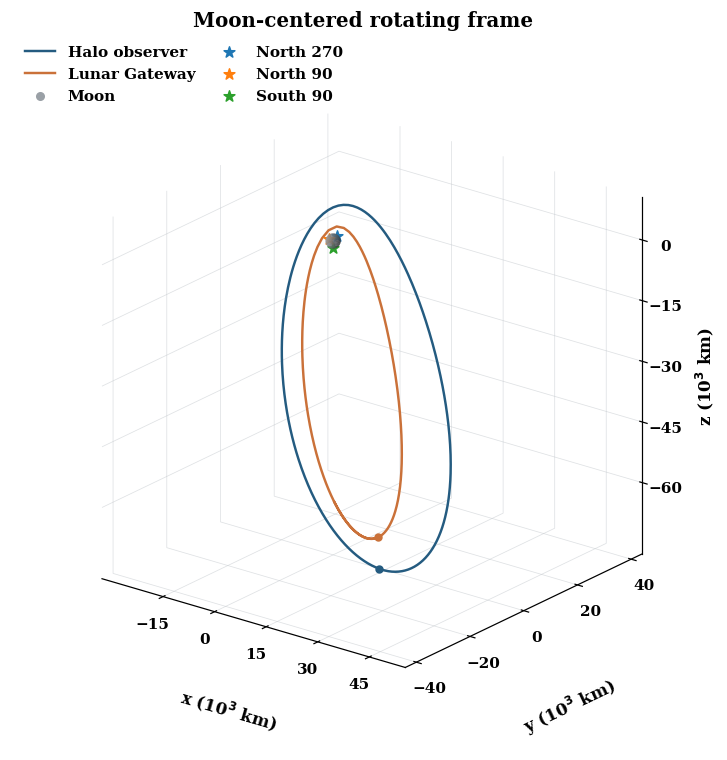

In [4]:
from halo_tracking.plotting import geometry, observer_knowledge, gateway_comparison_figures, state_histories, export
fig_geometry = geometry(result)
export(fig_geometry, ROOT / "results/gateway_comparison/geometry.png")

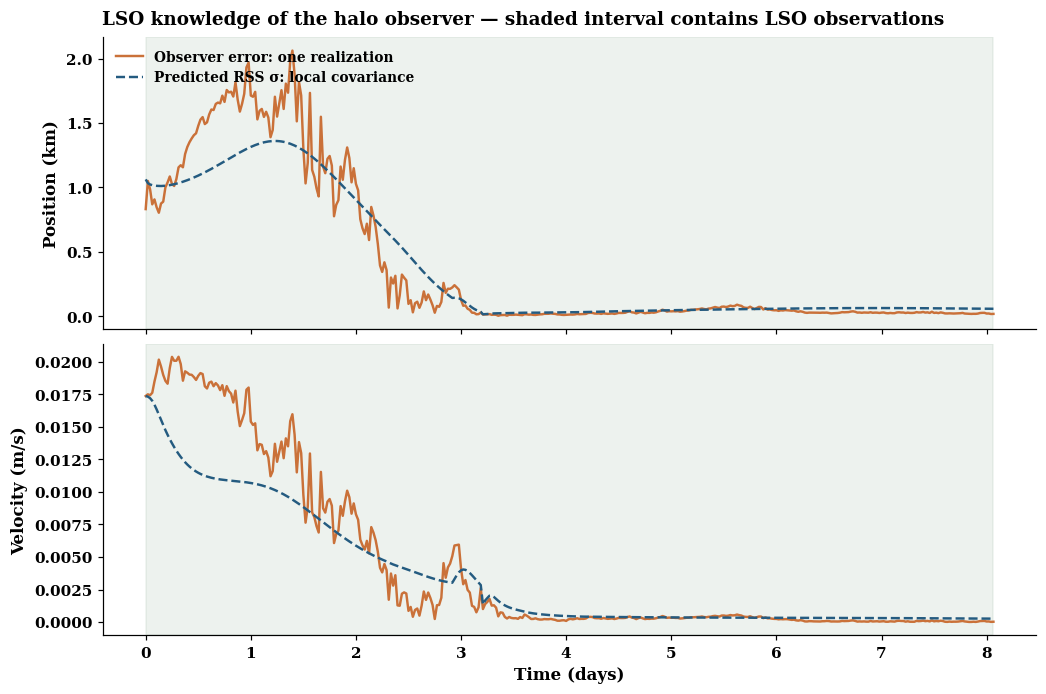

In [5]:
fig_observer = observer_knowledge(result)
export(fig_observer, ROOT / "results/gateway_comparison/observer.png")

## Observer position, velocity and acceleration

The solid curve is the perfect observer state (truth); the dashed curve is the LSO-predicted state. Components use Moon-centered inertial axes. These curves nearly overlap at orbit scale; the error plot above resolves their differences.

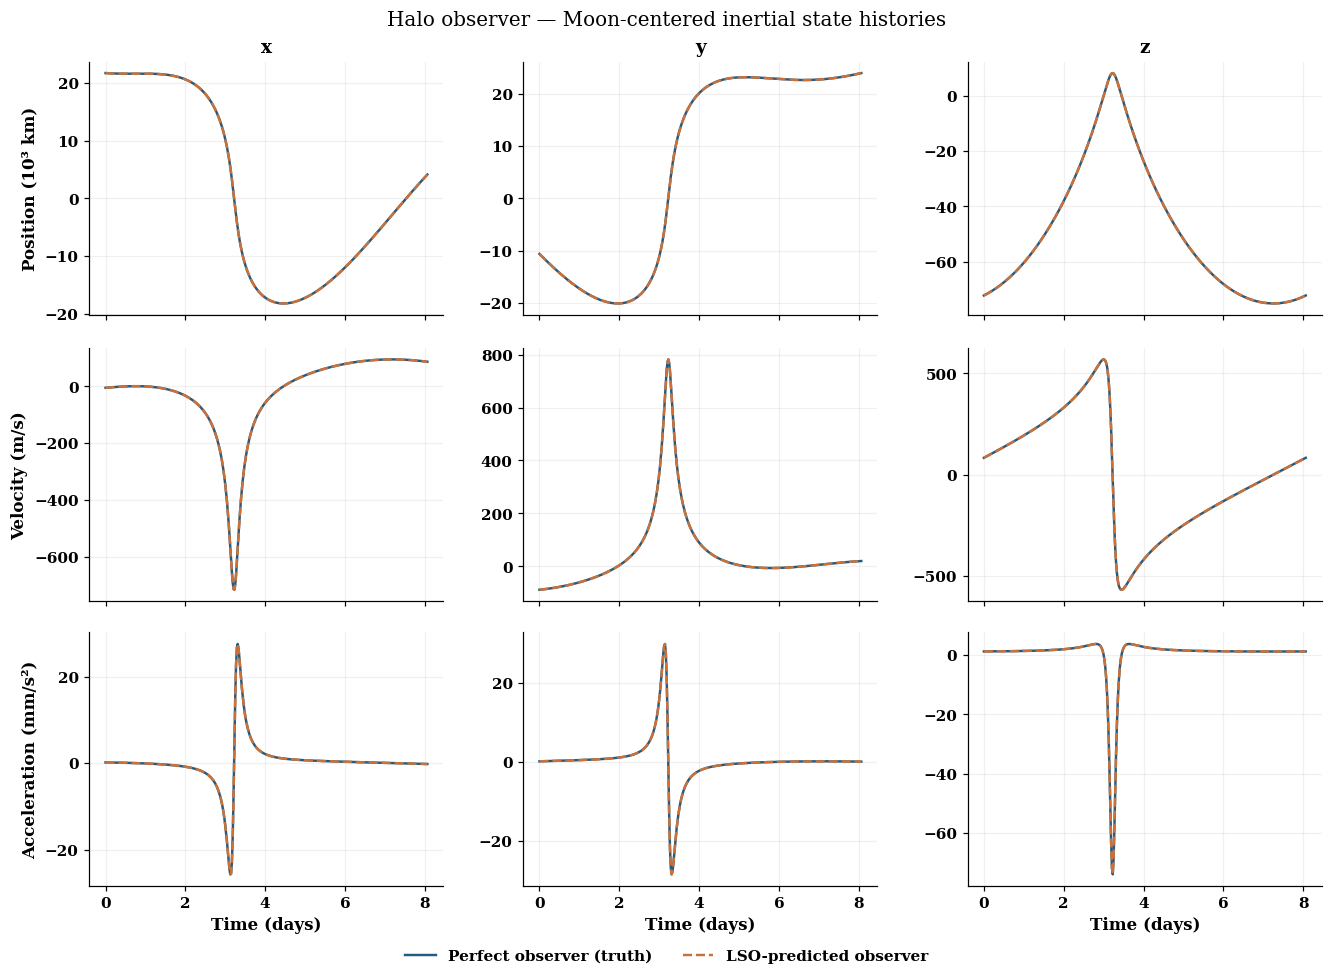

In [6]:
fig_observer_states = state_histories(result, 'observer')
export(fig_observer_states, ROOT / 'results/gateway_comparison/observer_states.png')

## Gateway position, velocity and acceleration

Compare the true Gateway trajectory with the two tracked trajectories: one uses the perfect observer and one uses the LSO-predicted observer. Their small separation is quantified by the error plot and RMSE table below.

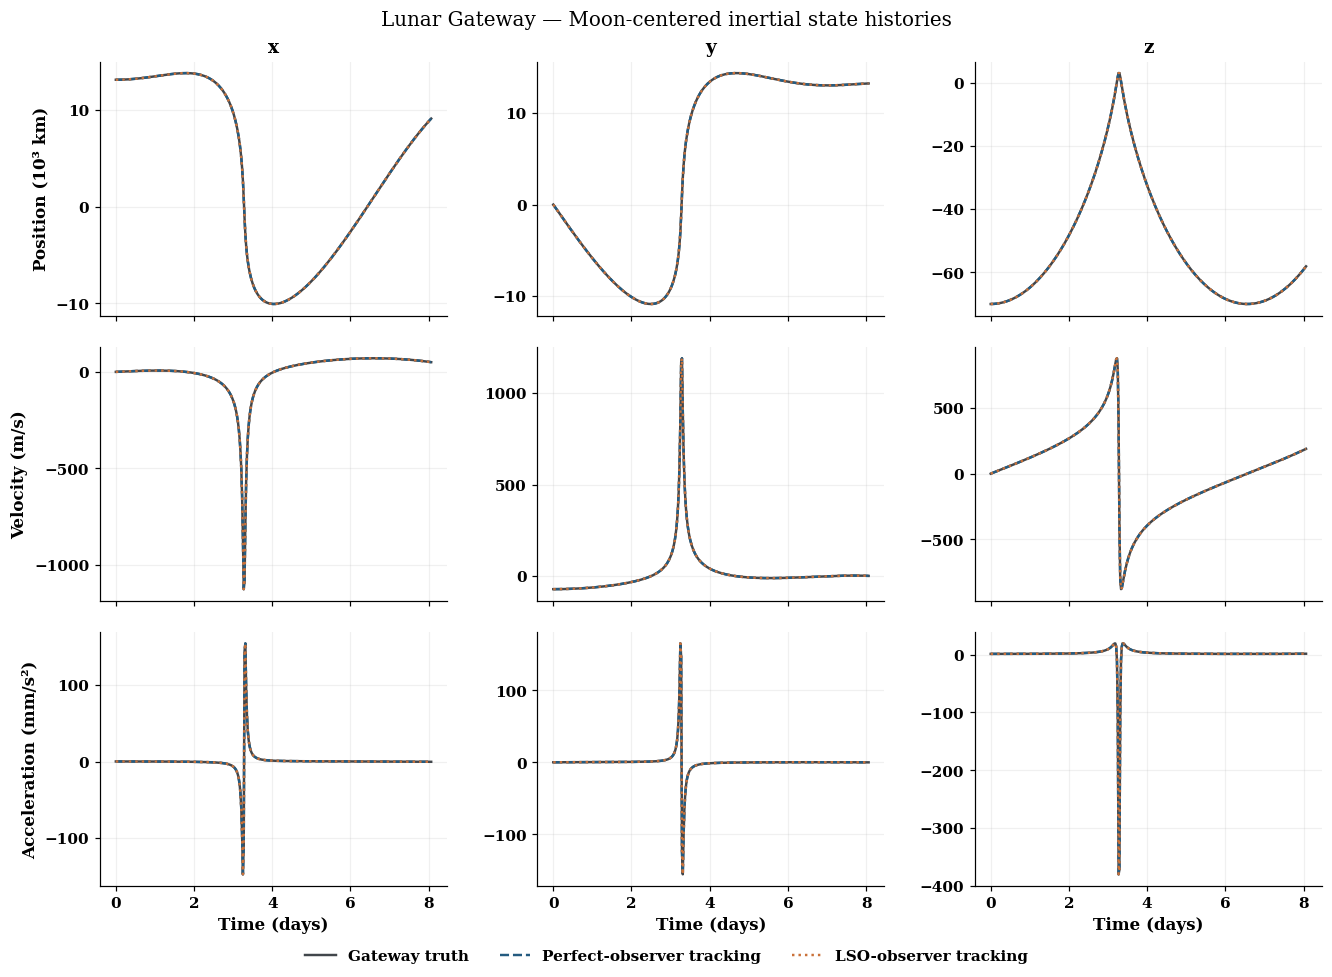

In [7]:
fig_gateway_states = state_histories(result, 'gateway')
export(fig_gateway_states, ROOT / 'results/gateway_comparison/gateway_states.png')

## 3. What changes in Gateway tracking

**Actual-error plot:** distance between the estimated and true Gateway state in this one shared noise realization. Lower is better. It is an actual orbit estimate, not just a pointing-error projection.

**Predicted-uncertainty plot:** square root of the position/velocity covariance-block trace. Lower means the estimator predicts better knowledge. These are local linearized predictions; they can be optimistic if the approximation is inaccurate.

In the imperfect case, the estimator carries observer–Gateway cross-covariance through time. Gateway measurements do not refine the observer: its state knowledge comes from the LSO. LSO updates can also correct Gateway indirectly through the retained correlation.

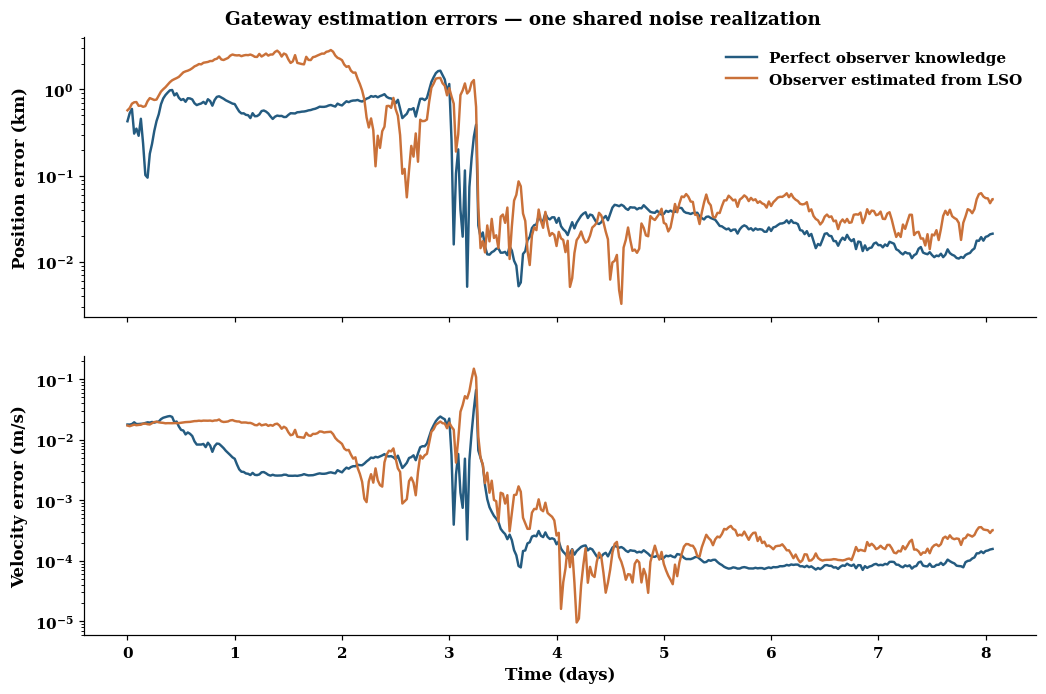

In [8]:
figures = gateway_comparison_figures(result)
fig_errors = figures["errors"]
export(fig_errors, ROOT / "results/gateway_comparison/errors.png")
import matplotlib.pyplot as plt
plt.close(figures["uncertainty"])

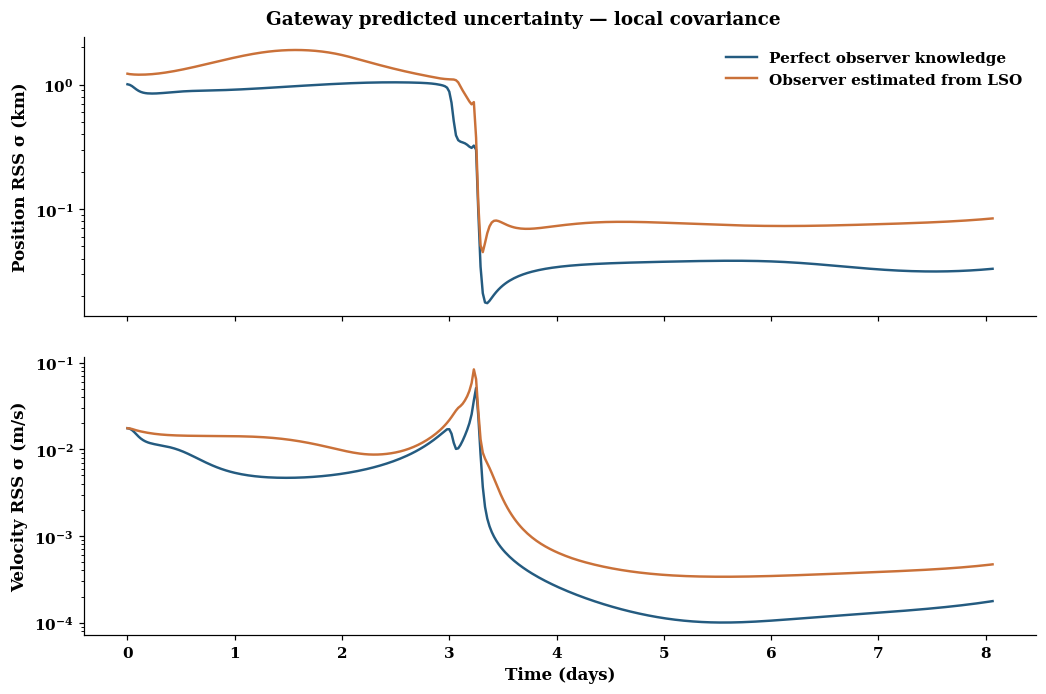

In [9]:
figures_uncertainty = gateway_comparison_figures(result)
plt.close(figures_uncertainty["errors"])
fig_uncertainty = figures_uncertainty["uncertainty"]
export(fig_uncertainty, ROOT / "results/gateway_comparison/uncertainty.png")

## 4. Numerical conclusions

The table separates **actual errors from one realization** from **predicted uncertainty**. It should be read with the assumptions above, especially the Gateway prior and observing geometry.

In [10]:
rows=[]
for key,label in [("perfect","Perfect observer knowledge"),("lso_estimated","Observer estimated from LSO")]:
    item=report[key]
    values=[label, f"{1000*item['position_rmse_km']:.1f}", f"{item['velocity_rmse_m_s']:.4f}",
            f"{1000*item['final_position_error_km']:.1f}",
            f"{1000*item['final_position_forecast_rss_sigma_km']:.1f}",
            f"{item['final_velocity_error_m_s']:.3g}"]
    rows.append("<tr>"+"".join("<td>"+v+"</td>" for v in values)+"</tr>")
headers=["Observer knowledge", "Gateway position RMSE over arc (m)", "Gateway velocity RMSE over arc (m/s)", "Final actual position error (m)", "Final predicted position RSS σ (m)", "Final actual velocity error (m/s)"]
display(HTML("<table><tr>"+"".join("<th>"+v+"</th>" for v in headers)+"</tr>"+"".join(rows)+"</table>"))

Observer knowledge,Gateway position RMSE over arc (m),Gateway velocity RMSE over arc (m/s),Final actual position error (m),Final predicted position RSS σ (m),Final actual velocity error (m/s)
Perfect observer knowledge,443.9,0.0077,21.2,33.1,0.000157
Observer estimated from LSO,1096.9,0.0152,53.2,84.0,0.000321


In [11]:
import numpy as np
ideal=report["perfect"]; estimated=report["lso_estimated"]
ratio=estimated["final_position_forecast_rss_sigma_km"]/ideal["final_position_forecast_rss_sigma_km"]
available=np.flatnonzero(result["lso_available"])
start=result["times"][available[0]]*cfg["time_unit_s"]/86400 if len(available) else float("nan")
end=result["times"][available[-1]]*cfg["time_unit_s"]/86400 if len(available) else float("nan")
conclusions = f"""
- Final predicted Gateway position RSS σ: **{1000*ideal['final_position_forecast_rss_sigma_km']:.1f} m** with exact observer knowledge versus **{1000*estimated['final_position_forecast_rss_sigma_km']:.1f} m** with LSO-estimated knowledge ({ratio:.1f}×).
- Final actual position errors: **{1000*ideal['final_position_error_km']:.1f} m** versus **{1000*estimated['final_position_error_km']:.1f} m** in this realization.
- The network supplies **{int(result['sensor_visible'].sum())} site observations** across **{int(result['lso_available'].sum())} scheduled epochs**. Overlapping sites provide separate measurements.
- These EKF results illustrate ideal versus measured state knowledge. They are a benchmark, not an identified model or an ensemble accuracy claim.
"""
display(Markdown(conclusions))


- Final predicted Gateway position RSS σ: **33.1 m** with exact observer knowledge versus **84.0 m** with LSO-estimated knowledge (2.5×).
- Final actual position errors: **21.2 m** versus **53.2 m** in this realization.
- The network supplies **446 site observations** across **388 scheduled epochs**. Overlapping sites provide separate measurements.
- These EKF results illustrate ideal versus measured state knowledge. They are a benchmark, not an identified model or an ensemble accuracy claim.


## Model and limitations

Propagation uses the Earth–Moon CR3BP. The plots transform normalized rotating states into Moon-centered inertial position, velocity and acceleration. Acceleration is calculated from each state using the dynamics; it is not independently estimated.

The imperfect case retains observer–Gateway cross-covariance. LSO measurements update observer knowledge; Gateway measurements update Gateway without refining the observer. Initial covariances are diagonal, with zero observer–Gateway cross-covariance. The forecast uses zero innovations along the nominal trajectories; the actual estimate uses noisy measurements.

The supplied `SNRHL2` state is a southern NRHO initial condition rounded to four decimals. Its one-period closure miss is about 99 km. This study assumes no stationkeeping or unmodeled forces. Local filter covariance can be overconfident near nonlinear updates, so predicted uncertainty is a conditional comparison rather than a validated error bound.

Gateway's initial state comes from [the earlier cislunar project](https://github.com/scottblender/Gradient-Free-Optimization-for-Cislunar-SDA-2/blob/main/scripts/build_target_case_database.m). Both phases start at model time zero, without a mission epoch. Both trajectories use LU = 384400 km and TU = 375190.25852 s; the source Gateway project used TU = 375695 s.

## System identification — step 1: generate data

**Goal:** learn a local, unforced state-transition model that predicts the observer's next position and velocity. No model is fitted in this step.

Generate 20 training, 5 validation and 5 held-out test arcs. Each spans one nominal period, sampled uniformly every 30 minutes. Initial states are independently perturbed about the supplied state with 1 km and 0.01 m/s standard deviation per rotating-frame axis. These describe the local training domain, separately from the EKF's estimation prior.

Each file contains normalized rotating truth states, physical inertial position/velocity/acceleration, ideal angles, noisy angles and per-site visibility. Measured angles are NaN when unavailable. Training targets are the next normalized six-component state; the current state is the input. Truth states are simulation labels, not LSO position measurements.

Split by whole trajectory before constructing lag windows. Fit normalization using training data only; use validation for model selection and test data once for final assessment. Do not use invisible ideal angles as observations. The current dataset covers nearby initial conditions at one nominal phase, with no thrust or model discrepancy; it does not yet support stationkeeping identification.

In [12]:
from halo_tracking.identification import generate_dataset
identification_summary = generate_dataset(cfg, ROOT / 'results/system_identification')
headers = ['Split', 'Arcs', 'Samples / arc', 'Transitions', 'Network visibility']
rows = ''.join('<tr>' + ''.join(f'<td>{value}</td>' for value in
    [name, item['arcs'], item['samples_per_arc'], item['transitions'], f"{100*item['visible_fraction']:.1f}%"])
    + '</tr>' for name, item in identification_summary.items())
display(HTML('<table><tr>' + ''.join(f'<th>{h}</th>' for h in headers) + '</tr>' + rows + '</table>'))

Split,Arcs,Samples / arc,Transitions,Network visibility
training,20,388,7740,100.0%
validation,5,388,1935,100.0%
test,5,388,1935,100.0%
